# Week 5 Project: Linear Model Pipeline

**Dataset:** California Housing CSV (`data/california_housing.csv`, 20,640 rows, 8 numeric features + target)
**Goal:** build an honest, defendable linear-model pipeline: baseline, plain model, Ridge, Lasso, tuned alpha, interpretation, and one final test score.

**Three mistakes to avoid:** (1) skipping the baseline, (2) tuning on the test set, (3) no interpretation.

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing values per column (AveBedrms has some; we impute inside the pipelines):
MedInc           0
HouseAge         0
AveRooms         0
AveBedrms      207
Population       0
AveOccup         0
Latitude         0
Longitude        0
MedHouseVal      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20433.0,1.097062,0.476104,0.333333,1.006029,1.048889,1.099631,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


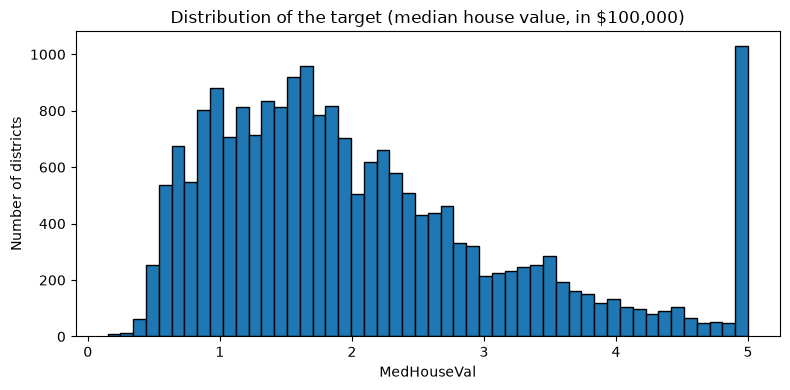

Share of rows at the maximum value: 0.0468


In [ ]:
# TASK 01: Load, explore, define the target
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline

warnings.filterwarnings("ignore")
Path("outputs").mkdir(exist_ok=True)          # folder for chart + table

DATA_PATH = Path("data/california_housing.csv")
df = pd.read_csv(DATA_PATH)
target_name = "MedHouseVal"                   # the column we want to predict

# Alternative (needs internet): the original scikit-learn version, 20,640 rows
# from sklearn.datasets import fetch_california_housing
# df = fetch_california_housing(as_frame=True).frame

print("Shape:", df.shape)
display(df.head())

print("\nData types:")
print(df.dtypes)
print("\nMissing values per column (AveBedrms has some; we impute inside the pipelines):")
print(df.isna().sum())

display(df.describe().T)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df[target_name], bins=50, edgecolor="black")
ax.set_title("Distribution of the target (median house value, in $100,000)")
ax.set_xlabel(target_name)
ax.set_ylabel("Number of districts")
plt.tight_layout()
fig.savefig("outputs/target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Share of rows at the maximum value:", round((df[target_name] == df[target_name].max()).mean(), 4))

## Task 01: What it does and why
**Target (one sentence):** we predict the *median house value of a California census block group*, in units of $100,000. A higher value means a more expensive area.

**Data source:** local CSV in the `data/` folder: the 1990 California census block-group data in scikit-learn's column format (20,640 rows). Write where you got it in your README.

**Logic:** never model before you understand the data. We check shape, types, missing values, summary statistics and the target histogram.

**Features:** `MedInc` median income (units of $10,000) · `HouseAge` median house age (years) · `AveRooms` average rooms per household · `AveBedrms` average bedrooms per household · `Population` people in the block group · `AveOccup` average household size · `Latitude`, `Longitude` location.

**Look it up**
- *Why check the target distribution?* Skew, outliers or caps change how metrics behave and how well a linear model fits. The target is **capped at 5.0 ($500k)**, and about 4.7% of rows sit exactly at the cap. Prices above it are hidden, so models under-predict at the top.
- *Missing values:* `AveBedrms` has **207 missing values** (about 1%). Decision: fill them with the **median**, using `SimpleImputer` as the first step of every pipeline, so the median is learned from training data only (no leakage). Dropping 207 rows would also be acceptable, but imputing keeps all data.

**My observations (fill after running):** shape = ___ (expected (20640, 9)) · missing = ___ (expected 207 in AveBedrms) · missing = ___ · histogram shape = ___

In [12]:
# TASK 02: Split once, freeze the test set
X = df.drop(columns=target_name)
y = df[target_name]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

# One shared CV splitter so every model is compared on identical folds
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Collect every model's CV result here for the final comparison table
results = []
def record(name, scores):
    results.append({"Model": name, "CV R2 (mean)": scores.mean(), "CV R2 (std)": scores.std()})

X_train: (16512, 8) | X_test: (4128, 8)
y_train: (16512,) | y_test: (4128,)


## Task 02: What it does and why
**Logic:** split features (`X`) from target (`y`), then carve off 20% as a **frozen test set** (`random_state=42` makes it reproducible). We also create one shared 5-fold `KFold` so all models are scored on the *same* folds, which makes the comparison fair.

**Role of each part**
| Part | Purpose |
|---|---|
| Train (80%) | Learning the coefficients |
| Validation / CV (inside train) | Choosing models and alpha |
| Test (20%) | **One** final check at the very end |

**Look it up**
- *Why split BEFORE scaling or any data-derived choice?* Scaling computes a mean and standard deviation. If you compute them on all rows, information from the test rows leaks into training.
- *What is data leakage?* The model indirectly sees information from data it will later be judged on. The result is an optimistic score that will not hold on new data.

**My observations:** train rows = ___ · test rows = ___

In [13]:
# TASK 03: Dumb baseline
baseline = make_pipeline(SimpleImputer(strategy="median"), DummyRegressor(strategy="mean"))
baseline_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="r2")
record("Baseline (DummyRegressor, mean)", baseline_scores)

print("Baseline CV R2 per fold:", baseline_scores.round(3))
print("Baseline CV R2 mean    :", baseline_scores.mean().round(3))

Baseline CV R2 per fold: [-0. -0. -0. -0. -0.]
Baseline CV R2 mean    : -0.0


## Task 03: What it does and why
**Logic:** the imputer is the first step so the 207 gaps never crash a model. The dummy model always predicts the training-set mean price. It uses no features. Its R² is about **0** (slightly negative on some folds). This is your **floor**: every real model must beat it, otherwise something is wrong.

**Metric direction:** R² goes **up** as the model gets better. 1.0 is perfect, 0 means "no better than predicting the mean", and negative means worse than that.

**Look it up**
- *Why is a baseline useful even though it is not a real model?* It turns "R² = 0.60" from a meaningless number into "0.60 versus a no-skill floor of 0".
- *What does `cross_val_score` do?* It splits the training data into k folds, trains on k-1 folds, scores on the held-out fold, repeats k times and returns k scores. It beats a single split because one split can be lucky or unlucky; averaging k splits is more stable and its standard deviation shows the uncertainty.

**My observations:** baseline CV R² = ___

In [14]:
# TASK 04: Plain, unscaled linear regression
lr = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
lr_scores = cross_val_score(lr, X_train, y_train, cv=cv, scoring="r2")
record("Plain LinearRegression (no scaling)", lr_scores)

lr.fit(X_train, y_train)
raw_coefs = pd.Series(lr[-1].coef_, index=X_train.columns)

print("Plain LR CV R2 mean:", lr_scores.mean().round(3))
print("\nRaw coefficients:")
print(raw_coefs.round(6))
print("\nCoefficient range:", raw_coefs.min().round(4), "to", raw_coefs.max().round(4))
print("Feature value ranges (max - min):")
print((X_train.max() - X_train.min()).round(2))

Plain LR CV R2 mean: 0.611

Raw coefficients:
MedInc        0.448675
HouseAge      0.009724
AveRooms     -0.123323
AveBedrms     0.783145
Population   -0.000002
AveOccup     -0.003526
Latitude     -0.419792
Longitude    -0.433708
dtype: float64

Coefficient range: -0.4337 to 0.7831
Feature value ranges (max - min):
MedInc           14.50
HouseAge         51.00
AveRooms        141.02
AveBedrms        25.30
Population    35679.00
AveOccup       1242.64
Latitude          9.40
Longitude        10.04
dtype: float64


## Task 04: What it does and why
**Logic:** fit a plain `LinearRegression` with no preprocessing, then look at the raw coefficients next to the feature ranges. Each coefficient means "change in price per **1 raw unit** of that feature". Because the units differ wildly (`Population` goes into the thousands, `AveBedrms` is around 1), the coefficients are **not comparable**. A tiny `Population` coefficient does not mean it is unimportant.

**Honest nuance:** plain least squares gives the *same predictions* with or without scaling. Scaling does not change its accuracy. It matters for (a) comparing coefficients and (b) Ridge/Lasso, whose penalty depends on coefficient size.

**Look it up**
- *Why are linear models scale-sensitive but trees are not?* A linear model multiplies each feature by a coefficient, so the feature's units decide the coefficient's size, and a penalty treats all coefficients alike. A tree only asks "is the value above a threshold?", and any order-preserving rescaling gives the same splits.
- *Does it beat the baseline?* It should, by a wide margin (R² about 0.61 versus about 0), because the features carry real signal, especially `MedInc` and location.

**My observations:** plain LR CV R² = ___ · baseline = ___ · which coefficients look tiny or huge = ___

In [15]:
# TASK 05: Ridge and Lasso on standardised features
scaled_ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge())    # default alpha = 1.0
scaled_lasso = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Lasso())    # default alpha = 1.0

ridge_scores = cross_val_score(scaled_ridge, X_train, y_train, cv=cv, scoring="r2")
lasso_scores = cross_val_score(scaled_lasso, X_train, y_train, cv=cv, scoring="r2")
record("Ridge (scaled, default alpha=1)", ridge_scores)
record("Lasso (scaled, default alpha=1)", lasso_scores)

print("Ridge CV R2:", ridge_scores.mean().round(3))
print("Lasso CV R2:", lasso_scores.mean().round(3))

scaled_ridge.fit(X_train, y_train)
scaled_lasso.fit(X_train, y_train)
coef_table = pd.DataFrame({
    "Ridge": scaled_ridge[-1].coef_,
    "Lasso": scaled_lasso[-1].coef_,
}, index=X_train.columns).round(4)
display(coef_table)
print("Exact zeros -> Ridge:", int((coef_table["Ridge"] == 0).sum()),
      "| Lasso:", int((coef_table["Lasso"] == 0).sum()))

Ridge CV R2: 0.611
Lasso CV R2: -0.0


,Ridge,Lasso
MedInc,0.8543,0.0
HouseAge,0.1226,0.0
AveRooms,-0.2942,0.0
AveBedrms,0.3390,0.0
Population,-0.0023,0.0
AveOccup,-0.0408,0.0
Latitude,-0.8962,0.0
Longitude,-0.8691,0.0


Exact zeros -> Ridge: 0 | Lasso: 8


## Task 05: What it does and why
**Logic:** `make_pipeline(StandardScaler(), Ridge())` first standardises each feature (mean 0, std 1), then fits the regularised model. Both add a penalty to the loss: Ridge penalises the *squares* of coefficients (L2), Lasso their *absolute values* (L1).

**Expected surprise:** with the default `alpha=1.0`, Lasso on standardised California data is usually **far too strong**. It shrinks most or all coefficients to exactly 0 and behaves like the baseline (R² near 0). Ridge at alpha=1 stays close to the plain model. This is why Task 06 tunes alpha.

**Look it up**
- *Why scale before Ridge/Lasso but not necessarily before LinearRegression?* The penalty is applied to coefficient *size*. A feature measured in small units needs a large coefficient and would be penalised unfairly. Standardising puts every feature on equal footing. Plain least squares has no penalty, so predictions are unchanged.
- *Which gives exact zeros, and why?* **Lasso.** The L1 penalty has "corners" on the axes, so the optimum often lands exactly on zero. Ridge's smooth L2 penalty only shrinks values toward zero without reaching it.
- *What does alpha control?* The trade-off between fit and simplicity. Small alpha means a flexible model close to plain regression (more variance, risk of overfitting). Large alpha means strong shrinkage (more bias, risk of underfitting).

**My observations:** Ridge R² = ___ · Lasso R² = ___ · zeros in Lasso = ___

In [16]:
# TASK 06: Tune alpha with cross-validation (training data only)
lasso_cv = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10], cv=5)
)
lasso_cv.fit(X_train, y_train)
best_alpha = lasso_cv.named_steps["lassocv"].alpha_
lasso_coefs = lasso_cv.named_steps["lassocv"].coef_

print("Best Lasso alpha:", best_alpha)
print("Zeroed coefficients:", int((lasso_coefs == 0).sum()), "of", len(lasso_coefs))
lasso_cv_scores = cross_val_score(lasso_cv, X_train, y_train, cv=cv, scoring="r2")
print("Tuned Lasso CV R2:", lasso_cv_scores.mean().round(3))
record("Lasso tuned (LassoCV)", lasso_cv_scores)

# Same idea for Ridge so the comparison is fair
ridge_cv = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000]))
ridge_cv.fit(X_train, y_train)
print("\nBest Ridge alpha:", ridge_cv.named_steps["ridgecv"].alpha_)
ridge_cv_scores = cross_val_score(ridge_cv, X_train, y_train, cv=cv, scoring="r2")
print("Tuned Ridge CV R2:", ridge_cv_scores.mean().round(3))
record("Ridge tuned (RidgeCV)", ridge_cv_scores)

Best Lasso alpha: 0.001
Zeroed coefficients: 0 of 8
Tuned Lasso CV R2: 0.611

Best Ridge alpha: 1.0
Tuned Ridge CV R2: 0.606


## Task 06: What it does and why
**Logic:** `LassoCV` tries every alpha in the grid with 5-fold CV on the **training data only** and keeps the alpha with the lowest validation error. We then count the coefficients it zeroed out (the feature-selection story) and do the same tuning for Ridge for a fair comparison.

**Look it up**
- *Why is CV a better estimate than one fixed validation split?* The score no longer depends on which rows happened to land in one validation set. It uses every training row for validation exactly once.
- *Effect of alpha:* larger alpha means coefficients shrink toward zero (Lasso: more exact zeros); smaller alpha means coefficients approach the plain regression values.
- *Why never choose alpha by peeking at the test set?* Then the test set takes part in model selection, so its score is optimistically biased and no longer an honest estimate of unseen data. That is Mistake 2.

**Reading the result:** the tuned alpha is small, so Lasso keeps almost all features. With only 8 features and 16,000+ training rows, there is little overfitting to fix. Expect tuned Ridge and Lasso to land very close to plain LR. That is an honest finding, not a failure.

**My observations:** best Lasso alpha = ___ · zeros = ___ · best Ridge alpha = ___ · scores vs plain = ___

In [17]:
# TASK 07: One clean Pipeline = the whole model
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1, 10], cv=5)),
])

pipeline.fit(X_train, y_train)
pipeline_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="r2")

print("Chosen alpha:", pipeline.named_steps["model"].alpha_)
print("Pipeline CV R2:", pipeline_scores.mean().round(3))
print("Matches Task 06 tuned Lasso CV R2:", np.isclose(pipeline_scores.mean(), lasso_cv_scores.mean()))

Chosen alpha: 0.001
Pipeline CV R2: 0.611
Matches Task 06 tuned Lasso CV R2: True


## Task 07: What it does and why
**Logic:** `Pipeline` chains the steps into one object. Calling `.fit()` fits the scaler *then* the model; calling `.predict()` or `.score()` scales new data with the stored training mean/std and then predicts. This single object **is** the model.

**Look it up**
- *Why does the Pipeline stop leakage, even at the final test evaluation?* Inside `cross_val_score`, the scaler is re-fit on each training fold only, never on the validation fold. On the test set, the pipeline only *transforms* with statistics learned from training data.
- *Fitting the Pipeline on `X_train` vs refitting inside `cross_val_score`?* `pipeline.fit(X_train, y_train)` trains the one object you keep. `cross_val_score` clones the pipeline and trains fresh copies per fold just to measure performance, and your fitted object is untouched.

**My observations:** CV R² matches Task 06? ___

,standardised coefficient
Latitude,-0.8858
Longitude,-0.8581
AveRooms,-0.2813
AveOccup,-0.0399
Population,-0.0011
HouseAge,0.1233
AveBedrms,0.3260
MedInc,0.8491


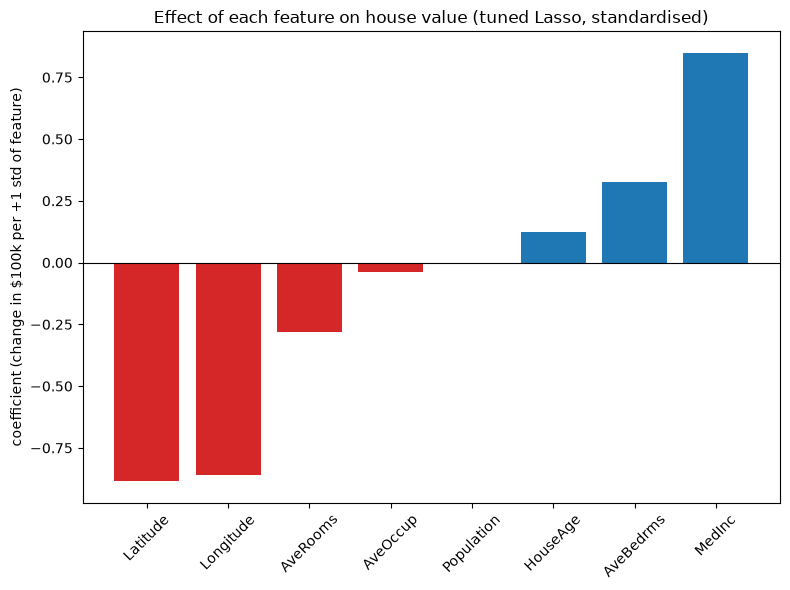

In [18]:
# TASK 08: Interpret the model
coefs = pd.Series(pipeline.named_steps["model"].coef_, index=X.columns).sort_values()
display(coefs.round(4).to_frame("standardised coefficient"))

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["tab:red" if c < 0 else "tab:blue" for c in coefs.values]
ax.bar(coefs.index, coefs.values, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Effect of each feature on house value (tuned Lasso, standardised)")
ax.set_ylabel("coefficient (change in $100k per +1 std of feature)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
fig.savefig("outputs/coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 08: What it does and why
**Logic:** after standardising, every coefficient means "change in predicted price (in $100k) for a +1 standard-deviation increase in that feature, holding the others fixed". That puts all features on one scale, so bar heights are directly comparable. Blue bars push price up, red bars push it down.

**Look it up**
- *Why standardised coefficients?* Raw coefficients depend on units. Standardised ones let you say which feature moves the prediction most.
- *What should you see?* `MedInc` is the strongest positive driver and `HouseAge` a smaller positive. `Latitude` and `Longitude` are large negatives (location matters a lot). `AveRooms` is negative and `AveBedrms` positive (opposite signs, because they are highly correlated). `Population` and `AveOccup` are close to zero.
- *Manager question this chart answers:* "What drives house prices in our data?" Answer: area income and location, with house size and crowding playing smaller roles.

**Write your 3-4 bullets here (plain language):**
- ___ (strongest positive driver and how confident you are)
- ___ (location effect)
- ___ (features near zero)
- ___ (caveat)

**Caveats to be honest about:** (1) coefficients show association, not causation; (2) `AveRooms`/`AveBedrms` (correlation about 0.85) and `Latitude`/`Longitude` (about -0.92) are strongly correlated, so their individual signs are unstable and should be read together; (3) a straight-line model cannot capture map-like location effects.

In [19]:
# TASK 09: Final test score (touched exactly once) + comparison table
from sklearn.metrics import mean_squared_error

final_test_r2 = pipeline.score(X_test, y_test)
final_rmse = float(np.sqrt(mean_squared_error(y_test, pipeline.predict(X_test))))
final_cv = pipeline_scores.mean()

print("FINAL test R2  :", round(final_test_r2, 3))
print("FINAL test RMSE:", round(final_rmse, 3), "(in $100k, i.e. about $", round(final_rmse * 100_000), ")")
print("CV R2 (train)  :", round(final_cv, 3), "| gap (CV - test):", round(final_cv - final_test_r2, 3))

comparison = pd.DataFrame(results)
comparison["Test R2 (final, once)"] = [
    round(final_test_r2, 3) if m == "Lasso tuned (LassoCV)" else "not evaluated"
    for m in comparison["Model"]
]
comparison[["CV R2 (mean)", "CV R2 (std)"]] = comparison[["CV R2 (mean)", "CV R2 (std)"]].round(3)

display(comparison)
comparison.to_csv("outputs/comparison_table.csv", index=False)
print("\nSaved: outputs/comparison_table.csv, outputs/coefficients.png, outputs/target_distribution.png")

FINAL test R2  : 0.577
FINAL test RMSE: 0.745 (in $100k, i.e. about $ 74456 )
CV R2 (train)  : 0.611 | gap (CV - test): 0.034


,Model,CV R2 (mean),CV R2 (std),"Test R2 (final, once)"
0,"Baseline (DummyRegressor, mean)",-0.000,0.000,not evaluated
1,Plain LinearRegression (no scaling),0.611,0.012,not evaluated
2,"Ridge (scaled, default alpha=1)",0.611,0.012,not evaluated
3,"Lasso (scaled, default alpha=1)",-0.000,0.000,not evaluated
4,Lasso tuned (LassoCV),0.611,0.012,0.577
5,Ridge tuned (RidgeCV),0.606,0.018,not evaluated



Saved: outputs/comparison_table.csv, outputs/coefficients.png, outputs/target_distribution.png


## Task 09: What it does and why
**Logic:** only now do we call the test set, **once**, on the final pipeline. The comparison table lists every variant with its CV score; only the final model gets a test score. Other models are deliberately *not* scored on test, because that would turn the test set into a selection tool.

**Look it up**
- *Did the test score over-promise?* Compare CV R² and test R². A gap of a few hundredths (for example CV 0.61 vs test 0.58) is normal and healthy. A large gap would signal leakage or overfitting.
- *Ridge or Lasso for this dataset?* With 8 meaningful, correlated features, Ridge is a natural fit (keep everything, shrink slightly). Lasso zeroes almost nothing at the tuned alpha (`Population` gets pushed to about 0). If you had hundreds of features, Lasso's selection would be the better story. Both land near plain regression in score, so the honest conclusion is that regularisation adds little when rows far outnumber features.
- *Most convincing chart and story:* the coefficient chart: income dominates price, backed by a defended test R² of about 0.58.

**Deliverable checklist**
- [ ] Notebook runs top to bottom
- [ ] Comparison table (`outputs/comparison_table.csv`)
- [ ] Saved coefficient chart (`outputs/coefficients.png`)
- [ ] Written interpretation (Task 08 bullets)
- [ ] README completed with your real numbers

**My observations:** test R² = ___ · RMSE = ___ · gap = ___ · final recommendation = ___